# Target Variable Analysis
A target variable is the variable that a Machine Learning model is designed to predict. Target variable analysis examines its values, distribution, class balance, and statistical properties before training a model.

# A – Target Analysis for Classification
##  Class Distribution
Definition
Class distribution describes how the observations in a classification target are spread across its different classes. It shows whether the classes are evenly represented or whether one class occurs much more frequently than others.
### Real-world example
- Analyze how many students passed and failed an examination.
- Examine how many patients have a particular condition compared with those who do not.
### Business example
- Analyze the proportion of customers who churn versus those who remain.
- Examine how many transactions are legitimate versus fraudulent.
### AI/ML use case
Class distribution helps data scientists understand the target before training a classifier. It can reveal imbalance that may affect model performance and the choice of evaluation metrics.

In [1]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.862 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [2]:
%mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.835 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


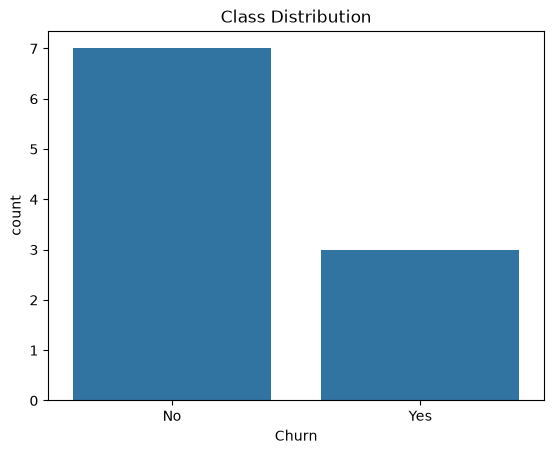

Churn
No     7
Yes    3
Name: count, dtype: int64


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Churn": [
        "No", "No", "No", "Yes", "No",
        "No", "Yes", "No", "No", "Yes"
    ]
})

sns.countplot(data=df, x="Churn")
plt.title("Class Distribution")
plt.show()

print(df["Churn"].value_counts())

### Explanation of the code
- Churn is the classification target.
- sns.countplot() displays the number of observations in each class.
- value_counts() calculates the class frequencies.
- The dataset contains seven non-churn customers and three churn customers.
- The chart and counts help us understand whether the target classes are balanced.

## Class Counts
Definition
Class counts represent the exact number of observations belonging to each target class. They provide the raw numbers needed to assess class representation before model training.
### Real-world example
- Count the number of students who passed and failed.
- Count the number of patients who tested positive and negative.
### Business example
- Count customers who renewed and did not renew their subscriptions.
- Count fraudulent and legitimate transactions in a payment dataset.
### AI/ML use case
Class counts help determine whether a classifier has sufficient examples of each class to learn meaningful patterns. Very small minority classes may require more data or special handling.

In [4]:
import pandas as pd

df = pd.DataFrame({
    "Result": [
        "Pass", "Pass", "Fail", "Pass",
        "Pass", "Fail", "Pass", "Pass"
    ]
})

class_counts = df["Result"].value_counts()

print(class_counts)
print("\nTotal observations:", len(df))

Result
Pass    6
Fail    2
Name: count, dtype: int64

Total observations: 8


### Explanation of the code
- value_counts() calculates the number of observations in each class.
- len(df) returns the total number of observations.
- The dataset contains six Pass observations and two Fail observations.
- These counts help us determine how many examples the model has for each outcome.

## Class Percentages
Definition
Class percentages express the proportion of observations belonging to each target class as a percentage of the entire dataset. They make it easier to compare class representation across datasets of different sizes.
### Real-world example
- Calculate the percentage of students who passed an examination.
- Calculate the percentage of survey participants who answered Yes or No.
### Business example
- Calculate the percentage of customers who churn.
- Calculate the percentage of fraudulent transactions among all transactions.
### AI/ML use case
Class percentages help identify minority classes and compare target balance across training, validation, and test datasets. They are also useful for monitoring changes in the target distribution over time.

In [5]:
import pandas as pd

df = pd.DataFrame({
    "Churn": [
        "No", "No", "No", "No", "No",
        "No", "No", "Yes", "Yes", "Yes"
    ]
})

percentages = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(percentages.round(2))

Churn
No     70.0
Yes    30.0
Name: proportion, dtype: float64


### Explanation of the code
- value_counts(normalize=True) calculates the proportion of each class.
- Multiplying by 100 converts the proportions into percentages.
- .round(2) rounds the results to two decimal places.
- The dataset contains 70% No and 30% Yes observations.
- Percentages help describe class distribution independently of the total number of records.

## Class Imbalance
Definition
Class imbalance occurs when one target class has substantially more observations than another class. It can cause a classifier to favor the majority class and perform poorly when identifying the minority class.
### Real-world example
- Most medical test results are negative, while only a small percentage are positive.
- Most network activities are normal, while a small percentage represent attacks.
### Business example
- Most customer transactions are legitimate, while only a small proportion are fraudulent.
- Most customers remain subscribed, while a smaller proportion cancel their subscriptions.
### AI/ML use case
Class imbalance can make accuracy misleading. Depending on the problem, data scientists may use class weighting, resampling, precision, recall, F1-score, or Precision-Recall AUC to evaluate and improve classification performance.

In [6]:
import pandas as pd

df = pd.DataFrame({
    "Fraud": ["No"] * 95 + ["Yes"] * 5
})

counts = df["Fraud"].value_counts()
percentages = df["Fraud"].value_counts(normalize=True) * 100

print("Counts:")
print(counts)

print("\nPercentages:")
print(percentages.round(2))

Counts:
Fraud
No     95
Yes     5
Name: count, dtype: int64

Percentages:
Fraud
No     95.0
Yes     5.0
Name: proportion, dtype: float64


### Explanation of the code
- The dataset contains 100 transactions.
- value_counts() calculates the class counts.
- normalize=True calculates the class proportions.
- The target has 95% No and 5% Yes observations, indicating substantial imbalance.
- A model that predicts No for every transaction achieves 95% accuracy but detects no fraud.
- Accuracy should therefore be considered alongside minority-class recall, precision, and other suitable metrics.

## Target Analysis for Regression
## Target Distribution
Definition
Target distribution describes how the numerical target values are spread across a dataset. It helps identify the overall shape, concentration of values, possible skewness, and unusual observations.
### Real-world example
- Analyze the distribution of house prices in a city.
- Examine the distribution of students' examination marks.
### Business example
- Study the distribution of monthly sales revenue.
- Analyze customer order values to determine whether most orders are small or large.
### AI/ML use case
Target distribution helps data scientists choose suitable regression metrics, identify extreme target values, and decide whether transformations or robust modeling techniques may be useful.

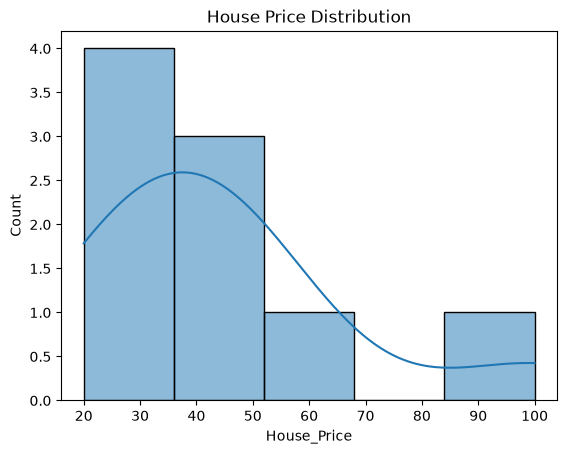

count      9.000000
mean      44.444444
std       23.775571
min       20.000000
25%       30.000000
50%       40.000000
75%       50.000000
max      100.000000
Name: House_Price, dtype: float64


In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "House_Price": [
        20, 25, 30, 35, 40, 45, 50, 55, 100
    ]
})

sns.histplot(df["House_Price"], bins=5, kde=True)
plt.title("House Price Distribution")
plt.show()

print(df["House_Price"].describe())

### Explanation of the code
- House_Price is the numerical target variable.
- sns.histplot() visualizes its distribution.
- kde=True adds a smooth density estimate.
- describe() summarizes the main statistical properties of the target.
- The value 100 is much larger than the other prices and deserves investigation, but it may be a valid expensive property.

## Mean of the Target
Definition
The mean is the arithmetic average of a numerical target variable, calculated by dividing the sum of its values by the number of observations. It provides a general measure of the target's center but can be affected by extreme values.
### Real-world example
- Calculate the average marks scored by students in an examination.
- Find the average height of people in a study.
### Business example
- Calculate the average monthly sales revenue.
- Find the average order value for an e-commerce business.
### AI/ML use case
The target mean provides a baseline for understanding the target and can be used to construct a simple baseline regression model that predicts the same average value for every observation.

In [8]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [100, 200, 300, 400, 1000]
})

print("Mean Sales:", df["Sales"].mean())

Mean Sales: 400.0


### Explanation of the code
- df["Sales"] selects the target column.
- mean() adds all five sales values and divides the total by five.
- The resulting mean is 400.
- A constant prediction of 400 can serve as a simple baseline for comparing regression models.

## Median of the Target
Definition
The median is the middle value of a numerical target after sorting the observations. It is a robust measure of center because it is generally less affected by extreme values than the mean.
### Real-world example
- Find the middle salary among a group of employees.
- Determine the typical home price using the median price of listed properties.
### Business example
- Calculate the median customer order value.
- Find the median delivery time to understand the typical delivery experience.
### AI/ML use case
The median helps identify skewed targets and provides a useful baseline for robust summaries. It is also useful when comparing a target's typical value with its mean.

In [9]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [100, 200, 300, 400, 1000]
})

print("Median Sales:", df["Sales"].median())

Median Sales: 300.0


### Explanation of the code
- median() sorts the five sales values and returns the middle observation.
- The median is 300.
- The mean is 400 because the large value of 1,000 pulls the average upward.
- Comparing mean and median helps us investigate whether the target is skewed.

## Variance of the Target
Definition
Variance measures how much numerical target values vary around their mean by calculating the average squared deviations. Sample variance divides by \(n-1\), while population variance divides by \(n\).
### Real-world example
- Compare how widely examination marks vary among two classrooms.
- Measure how much delivery times differ from the average delivery time.
### Business example
- Measure variability in monthly sales revenue.
- Compare fluctuations in product demand across different stores.
### AI/ML use case
Variance helps understand target variability and assess how much the target differs from its average. It is useful in statistical modeling and understanding the scale of prediction errors.

In [10]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [10, 20, 30, 40, 50]
})

print("Sample Variance:", df["Sales"].var())
print("Population Variance:", df["Sales"].var(ddof=0))

Sample Variance: 250.0
Population Variance: 200.0


### Explanation of the code
- var() calculates sample variance by default.
- ddof=0 calculates population variance.
- Sample variance divides the sum of squared deviations by \(n-1\).
- Population variance divides by \(n\).
- Variance is expressed in squared units, such as rupees squared when the target is measured in rupees.

## Standard Deviation of the Target
Definition
Standard deviation measures how much target values typically vary around their mean, expressed in the same units as the original target. A larger standard deviation indicates greater overall variability.
### Real-world example
- Measure how widely students' marks vary around the class average.
- Compare the variability of daily temperatures over two periods.
### Business example
- Measure how much daily revenue fluctuates around its average.
- Examine the variability of delivery times across orders.
### AI/ML use case
Standard deviation helps assess target variability, compare prediction errors with the target's natural spread, and understand the scale of the prediction problem.

In [11]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [10, 20, 30, 40, 50]
})

print("Standard Deviation:",
      round(df["Sales"].std(), 2))

Standard Deviation: 15.81


### Explanation of the code
- std() calculates the sample standard deviation.
- It takes the square root of sample variance.
- The result of 15.81 is expressed in the same units as Sales.
- Standard deviation is sensitive to extreme values, so it should be interpreted alongside other measures of spread.

## Skewness of the Target
Definition
Target skewness measures the asymmetry of the numerical target's distribution. Positive skew indicates a longer or heavier right tail, negative skew indicates a longer or heavier left tail, and a value near zero indicates little measured asymmetry.
### Real-world example
- House prices may be right-skewed because a few properties are exceptionally expensive.
- Examination scores may be left-skewed if most students score highly and a few score poorly.
### Business example
- Sales revenue may be right-skewed because a few days generate exceptionally high revenue.
- Insurance claim costs may be right-skewed because a small number of claims are very large.
### AI/ML use case
Skewness helps identify whether target transformations or robust evaluation approaches may be worth investigating. Some regression models can handle skewed targets, but transformations may improve certain models and prediction behavior.

In [12]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [10, 20, 30, 40, 100]
})

print("Target Skewness:",
      round(df["Sales"].skew(), 2))

Target Skewness: 1.7


### Explanation of the code
- skew() calculates sample skewness.
- The high sales value of 100 creates a right tail.
- Positive skewness indicates that the distribution extends further toward higher values.
- The exact value depends on the sample and the skewness convention.
- Skewness should be examined with a histogram and summary statistics before deciding whether to transform the target.

## Outliers in the Target
Definition
A target outlier is a target value that is unusually far from most other target observations. Such values can represent data errors, genuine extreme outcomes, or important rare events.
### Real-world example
- A house price is recorded as ₹50 crore when most properties in the dataset cost less than ₹1 crore.
- A student receives 999 marks in an examination whose maximum score is 100.
### Business example
- Daily revenue is unusually high because of a major promotional event.
- A delivery takes 100 days when most deliveries take fewer than five days.
### AI/ML use case
Extreme target values can strongly affect regression losses and model fitting. Data scientists should investigate them and consider robust losses, target transformations, or other approaches when appropriate.

In [13]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [10, 12, 13, 14, 15, 16, 18, 100]
})

Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower) |
    (df["Sales"] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Potential outliers:", outliers["Sales"].tolist())

Lower bound: 7.125
Upper bound: 22.125
Potential outliers: [100]


### Explanation of the code
- quantile() calculates the first and third quartiles.
- IQR measures the spread of the middle 50% of the target values.
- The lower and upper bounds are calculated using the 1.5 × IQR rule.
- The value 100 is flagged because it exceeds the upper bound.
- A flagged target should be checked against the original data before being removed or transformed.